# Анализ розничных данных с помощью множественной регрессии
Девять числовых факторов и категории. Отклик — логарифм total_price.
Результаты исследовательские: данные уже изучались в предыдущей версии.
Запуск всех ячеек сохраняет таблицы, графики и результаты в каталог проекта.

In [1]:
from pathlib import Path
import hashlib
import json
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'retail_price.csv').exists():
    ROOT = ROOT / 'scienceWork'
assert (ROOT / 'retail_price.csv').exists(), 'Run from the project directory'
for folder in ['results', 'figures', 'report_tables', 'appendix']:
    (ROOT / folder).mkdir(exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})
SEED = 20261030

def table(name, data):
    data.to_csv(ROOT / 'results' / (name + '.csv'), index=False)
    display(data.round(5))

def figure(name):
    plt.tight_layout()
    plt.savefig(ROOT / 'figures' / (name + '.png'), dpi=170,
                bbox_inches='tight')
    plt.show()
    plt.close()

## 1. Проверка данных и выбор признаков
Строки сохраняются, если нет ошибок. Крайние значения автоматически не удаляем.
Названия и единицы из источника документированы в DatasetInfo.md.

In [2]:
raw = pd.read_csv(ROOT / 'retail_price.csv')
df = raw.copy()
df['date'] = pd.to_datetime(df['month_year'], format='%d-%m-%Y')
log_fields = ['total_price', 'customers', 'comp_1', 'comp_2', 'comp_3',
              'product_weight_g', 'volume']
checks = {
    'rows': len(df), 'products': df.product_id.nunique(),
    'categories': df.product_category_name.nunique(),
    'months': df.date.nunique(), 'missing': int(raw.isna().sum().sum()),
    'duplicates': int(raw.duplicated().sum()),
    'duplicate_product_month': int(df.duplicated(['product_id', 'date']).sum()),
    'nonpositive_log_values': int((df[log_fields] <= 0).sum().sum()),
    'negative_freight': int((df.freight_price < 0).sum()),
    'zero_freight': int((df.freight_price == 0).sum()),
    'calendar_mismatch': int(((df.date.dt.month != df.month) |
                              (df.date.dt.year != df.year)).sum()),
}
for name in ['missing', 'duplicates', 'duplicate_product_month',
             'nonpositive_log_values', 'negative_freight', 'calendar_mismatch']:
    assert checks[name] == 0, (name, checks[name])
assert np.isfinite(df.select_dtypes('number')).all().all()
assert df.groupby('product_id').product_category_name.nunique().max() == 1
relative_gap = abs(df.total_price - df.unit_price * df.qty) / df.total_price
checks['identity_within_0_3_percent'] = int((relative_gap < 0.003).sum())
checks['identity_max_gap'] = float(relative_gap.max())
checks['category_month_customer_max_unique'] = int(df.groupby(
    ['product_category_name', 'date']).customers.nunique().max())
checks['start'] = str(df.date.min().date())
checks['end'] = str(df.date.max().date())
for col in log_fields:
    df['ln_' + col] = np.log(df[col])
BASE = ['ln_customers', 'ln_comp_1', 'ln_comp_2', 'ln_comp_3',
        'ln_product_weight_g', 'product_photos_qty']
EXTRA = ['product_score', 'ln_volume', 'freight_price']
FACTORS = BASE + EXTRA
LABELS = dict(zip(FACTORS, ['Покупатели', 'Конкурент 1', 'Конкурент 2',
    'Конкурент 3', 'Вес', 'Фотографии', 'Рейтинг', 'Объём', 'Доставка']))
category_counts = df.groupby('product_category_name').agg(
    rows=('product_id', 'size'), products=('product_id', 'nunique'),
    median_total=('total_price', 'median')).reset_index()
# Ties are resolved lexicographically, without using the outcome.
base_category = category_counts.sort_values(
    ['products', 'product_category_name'], ascending=[False, True]).iloc[0, 0]
categories = [base_category] + sorted(set(df.product_category_name) - {base_category})
DUMMIES = ['cat_' + c for c in categories[1:]]

def design(data, factors, categorical=False):
    X = data[factors].astype(float).copy()
    if categorical:
        for cat, col in zip(categories[1:], DUMMIES):
            X[col] = (data.product_category_name == cat).astype(float)
    return sm.add_constant(X, has_constant='add')

checks['base_category'] = base_category
print(json.dumps(checks, ensure_ascii=False, indent=2))
table('categories', category_counts)
audit = []
for c in raw.columns:
    row = {'column': c, 'dtype': str(raw[c].dtype),
           'missing': int(raw[c].isna().sum()), 'unique': raw[c].nunique()}
    if pd.api.types.is_numeric_dtype(raw[c]):
        row.update(min=float(raw[c].min()), max=float(raw[c].max()),
            varying_products=int((df.groupby('product_id')[c].nunique() > 1).sum()))
    audit.append(row)
table('column_audit', pd.DataFrame(audit))

{
  "rows": 676,
  "products": 52,
  "categories": 9,
  "months": 20,
  "missing": 0,
  "duplicates": 0,
  "duplicate_product_month": 0,
  "nonpositive_log_values": 0,
  "negative_freight": 0,
  "zero_freight": 1,
  "calendar_mismatch": 0,
  "identity_within_0_3_percent": 643,
  "identity_max_gap": 0.03058306418099551,
  "category_month_customer_max_unique": 1,
  "start": "2017-01-01",
  "end": "2018-08-01",
  "base_category": "garden_tools"
}


,product_category_name,rows,products,median_total
0,bed_bath_table,61,5,764.100
1,computers_accessories,69,6,1099.000
2,consoles_games,22,2,224.050
3,cool_stuff,57,5,799.920
4,furniture_decor,48,4,477.100
5,garden_tools,160,10,723.500
6,health_beauty,130,10,857.355
7,perfumery,26,2,650.180
8,watches_gifts,103,8,1604.000


,column,dtype,missing,unique,min,max,varying_products
0,product_id,str,0,52,NaN,NaN,NaN
1,product_category_name,str,0,9,NaN,NaN,NaN
2,month_year,str,0,20,NaN,NaN,NaN
3,qty,int64,0,66,1.00000,122.00,52.0
4,total_price,float64,0,573,19.90000,12095.00,52.0
5,freight_price,float64,0,653,0.00000,79.76,52.0
6,unit_price,float64,0,280,19.90000,364.00,50.0
7,product_name_lenght,int64,0,24,29.00000,60.00,0.0
8,product_description_lenght,int64,0,46,100.00000,3006.00,0.0
9,product_photos_qty,int64,0,7,1.00000,8.00,0.0


## 2. Распределения и описательные связи
Корреляции описательные: p-value с предположением независимости строк не считаем.

,variable,count,mean,std,min,25%,50%,75%,max
0,total_price,676.0,1422.70873,1700.12310,19.9,333.70000,807.89000,1887.32250,12095.00
1,customers,676.0,81.02811,62.05556,1.0,34.00000,62.00000,116.00000,339.00
2,comp_1,676.0,79.45205,47.93336,19.9,49.91000,69.90000,104.25655,349.90
3,comp_2,676.0,92.93008,49.48127,19.9,53.90000,89.99000,117.88889,349.90
4,comp_3,676.0,84.18264,47.74579,19.9,53.78571,59.90000,99.99000,255.61
5,product_weight_g,676.0,1847.49852,2274.80848,100.0,348.00000,950.00000,1850.00000,9750.00
6,volume,676.0,10664.62722,9172.80185,640.0,3510.00000,8000.00000,15750.00000,32736.00
7,product_photos_qty,676.0,1.99408,1.42047,1.0,1.00000,1.50000,2.00000,8.00
8,product_score,676.0,4.08550,0.23202,3.3,3.90000,4.10000,4.20000,4.50
9,freight_price,676.0,20.68227,10.08182,0.0,14.76191,17.51847,22.71356,79.76


,factor,pearson,spearman
0,ln_customers,0.43212,0.41039
1,ln_comp_1,0.13340,0.16462
2,ln_comp_2,0.27631,0.26093
3,ln_comp_3,0.21370,0.19785
4,ln_product_weight_g,0.14550,0.12843
5,product_photos_qty,0.01736,-0.01021
6,product_score,0.00164,-0.01719
7,ln_volume,0.01904,0.00882
8,freight_price,0.07841,0.17382


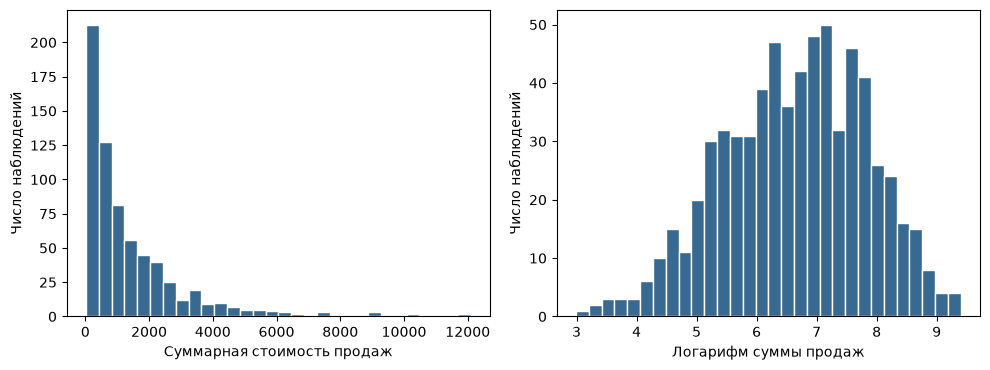

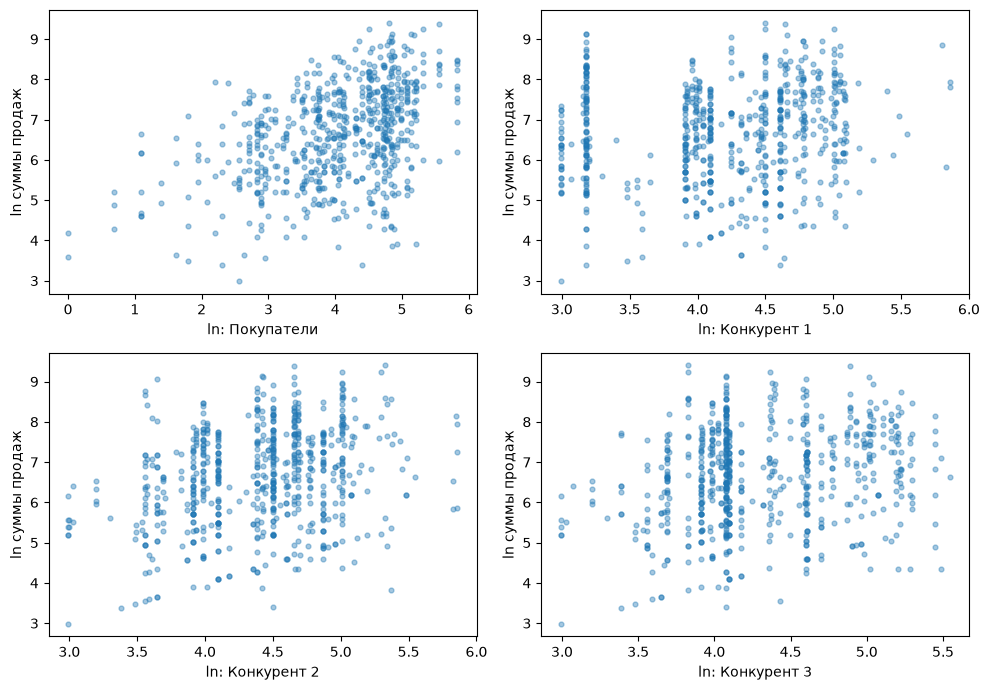

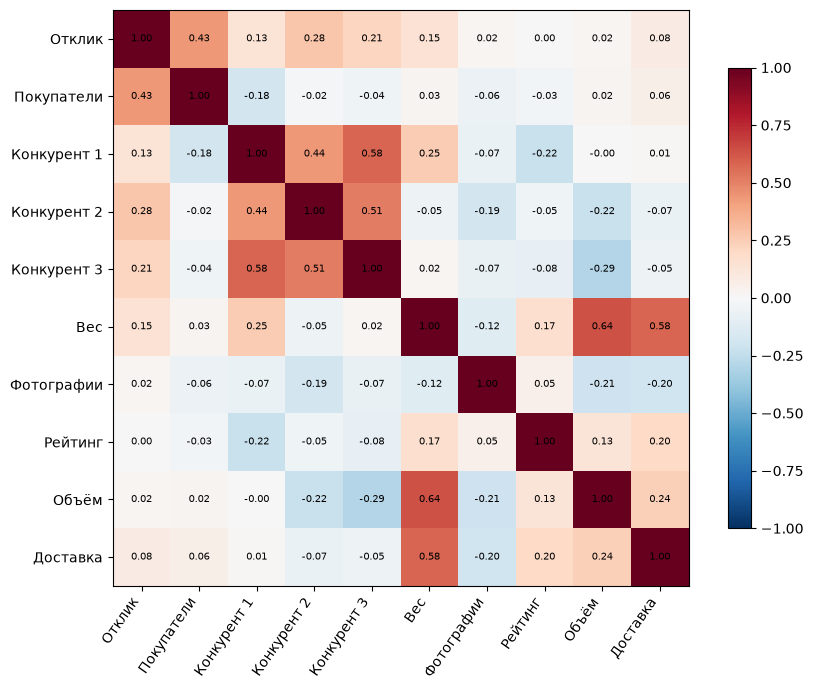

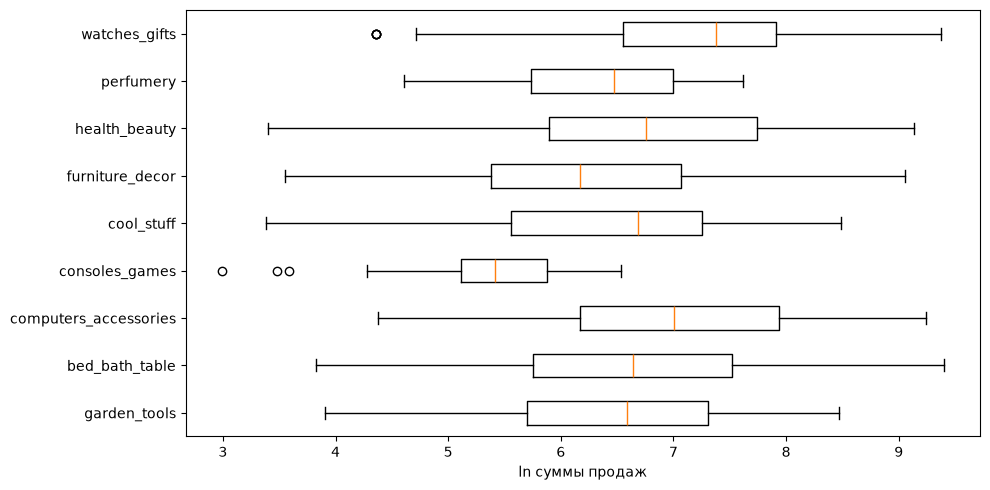

In [3]:
original = log_fields + ['product_photos_qty', 'product_score', 'freight_price']
desc = df[original].describe().T.reset_index(names='variable')
table('descriptive', desc)
pearson = df[['ln_total_price'] + FACTORS].corr()
spearman = df[['ln_total_price'] + FACTORS].corr(method='spearman')
pearson.to_csv(ROOT / 'results' / 'pearson.csv')
spearman.to_csv(ROOT / 'results' / 'spearman.csv')
table('target_correlations', pd.DataFrame({'factor': FACTORS,
    'pearson': pearson.loc[FACTORS, 'ln_total_price'].values,
    'spearman': spearman.loc[FACTORS, 'ln_total_price'].values}))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, c, title in zip(ax, ['total_price', 'ln_total_price'],
                      ['Суммарная стоимость продаж', 'Логарифм суммы продаж']):
    a.hist(df[c], bins=30, color='#386a91', edgecolor='white')
    a.set(xlabel=title, ylabel='Число наблюдений')
figure('distributions')
fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for a, c in zip(ax.flat, BASE[:4]):
    a.scatter(df[c], df.ln_total_price, s=12, alpha=.4)
    a.set(xlabel='ln: ' + LABELS[c], ylabel='ln суммы продаж')
figure('relationships')
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(pearson, cmap='RdBu_r', vmin=-1, vmax=1)
labels = ['Отклик'] + [LABELS[c] for c in FACTORS]
ax.set_xticks(range(10), labels, rotation=55, ha='right')
ax.set_yticks(range(10), labels)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f'{pearson.iloc[i,j]:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, ax=ax, shrink=.8)
figure('correlations')
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([df.loc[df.product_category_name == c, 'ln_total_price']
            for c in categories], tick_labels=categories, orientation='horizontal')
ax.set_xlabel('ln суммы продаж')
figure('categories')

## 3. Фиксированные модели и кластерные проверки
M1: шесть факторов; M2: M1 + категория; M3: M2 + рейтинг, объём, доставка.
Стандартные ошибки CR1 по товару, поправка на число групп, use_t=True.

In [4]:
def fit_cluster(X, data):
    assert np.linalg.matrix_rank(X) == X.shape[1], 'Rank deficient design'
    ols = sm.OLS(data.ln_total_price, X).fit()
    robust = ols.get_robustcov_results(cov_type='cluster',
        groups=data.product_id.to_numpy(), use_correction=True,
        df_correction=True, use_t=True)
    return ols, robust

specs = {f'S{j}': (['ln_customers', f'ln_comp_{j}',
    'ln_product_weight_g', 'product_photos_qty'], False) for j in [1, 2, 3]}
specs.update({'M1': (BASE, False), 'M2': (BASE, True), 'M3': (FACTORS, True)})
fits, matrices, fit_rows = {}, {}, []
for name, (factors, categorical) in specs.items():
    X = design(df, factors, categorical)
    ols, robust = fit_cluster(X, df)
    fits[name] = (ols, robust)
    matrices[name] = X
    fit_rows.append({'model': name, 'n': int(ols.nobs), 'parameters': X.shape[1],
        'rank': np.linalg.matrix_rank(X), 'cov_rank': np.linalg.matrix_rank(robust.cov_params()),
        'r2': ols.rsquared, 'adjusted_r2': ols.rsquared_adj})
# Sensitivity only: 19 calendar year-month indicators, base January 2017.
# Keep the same rows, factors, CR1 correction and product clusters.
month_labels = df.date.dt.to_period('M').astype(str)
month_indicators = pd.get_dummies(month_labels, prefix='time', drop_first=True,
                                  dtype=float)
assert month_indicators.shape[1] == 19
Xtime = pd.concat([matrices['M3'], month_indicators], axis=1)
fits['M3_time'] = fit_cluster(Xtime, df)
matrices['M3_time'] = Xtime
ols_time, robust_time = fits['M3_time']
fit_rows.append({'model': 'M3_time', 'n': int(ols_time.nobs),
    'parameters': Xtime.shape[1], 'rank': np.linalg.matrix_rank(Xtime),
    'cov_rank': np.linalg.matrix_rank(robust_time.cov_params()),
    'r2': ols_time.rsquared, 'adjusted_r2': ols_time.rsquared_adj})
table('model_comparison', pd.DataFrame(fit_rows))

coef_rows = []
for name, (ols, r) in fits.items():
    ci = r.conf_int()
    for j, col in enumerate(matrices[name].columns):
        coef_rows.append({'model': name, 'term': col, 'coef': r.params[j],
            'se': r.bse[j], 't': r.tvalues[j], 'p': r.pvalues[j],
            'low': ci[j,0], 'high': ci[j,1]})
coefs = pd.DataFrame(coef_rows)
coefs.to_csv(ROOT / 'results' / 'all_coefficients.csv', index=False)
main = coefs[(coefs.model == 'M3') & coefs.term.isin(FACTORS)].copy()
main['p_holm'] = multipletests(main.p, method='holm')[1]
main['holm_reject'] = main.p_holm < .05
table('main_coefficients', main)
time_coefficients = coefs[(coefs.model == 'M3_time') & coefs.term.isin(FACTORS)].copy()
time_coefficients['p_holm'] = multipletests(time_coefficients.p, method='holm')[1]
time_coefficients['holm_reject'] = time_coefficients.p_holm < .05
table('time_coefficients', time_coefficients)


# Reject singular restrictions rather than silently changing degrees of freedom.
def joint(model, cols, label):
    ols, r = fits[model]
    names = list(matrices[model].columns)
    A = np.eye(len(names))[[names.index(c) for c in cols]]
    rank = np.linalg.matrix_rank(A @ r.cov_params() @ A.T)
    if rank != len(cols):
        return dict(test=label, model=model, q=len(cols), rank=rank,
                    F=np.nan, p=np.nan, df_denom=np.nan)
    t = r.f_test(A)
    return dict(test=label, model=model, q=len(cols), rank=rank,
        F=float(t.fvalue), p=float(t.pvalue), df_denom=float(t.df_denom))

joint_rows = [joint('M3', BASE[1:4], 'competitors'),
    joint('M3', EXTRA, 'additional_block'),
    joint('M3', DUMMIES, 'categories'),
    joint('M3', FACTORS + DUMMIES, 'overall')]
Xq = matrices['M3'].copy()
Xq['customers_sq'] = (df.ln_customers - df.ln_customers.mean()) ** 2
matrices['M3q'] = Xq
fits['M3q'] = fit_cluster(Xq, df)
joint_rows.append(joint('M3q', ['customers_sq'], 'curvature'))
table('joint_tests', pd.DataFrame(joint_rows))
# Additional exploratory check; no search over alternative time specifications.
time_test = joint('M3_time', BASE[1:4], 'competitors_time')
table('time_joint_test', pd.DataFrame([time_test]))
time_rows = []
for model, coefficients, test in [
        ('M3', main, joint_rows[0]), ('M3_time', time_coefficients, time_test)]:
    time_rows.append({'model': model, 'n': len(df),
        'parameters': matrices[model].shape[1],
        'month_indicators': 19 if model == 'M3_time' else 0,
        'competitors_F': test['F'], 'competitors_p': test['p'],
        'weight_p_holm': float(coefficients.set_index('term').loc[
            'ln_product_weight_g', 'p_holm'])})
table('time_sensitivity', pd.DataFrame(time_rows))
print('Calendar check: the competitors result depends on specification. '
      'Failing to reject at 5% is not proof of no relationship.')

,model,n,parameters,rank,cov_rank,r2,adjusted_r2
0,S1,676,5,5,5,0.24393,0.23942
1,S2,676,5,5,5,0.30337,0.29922
2,S3,676,5,5,5,0.26266,0.25827
3,M1,676,7,7,7,0.31136,0.30518
4,M2,676,15,15,15,0.37429,0.36104
5,M3,676,18,18,18,0.39509,0.37946
6,M3_time,676,37,37,37,0.40712,0.37372


,model,term,coef,se,t,p,low,high,p_holm,holm_reject
38,M3,ln_customers,0.68640,0.06685,10.26757,0.00000,0.55219,0.82061,0.00000,True
39,M3,ln_comp_1,0.19483,0.14401,1.35289,0.18206,-0.09428,0.48394,0.72823,False
40,M3,ln_comp_2,0.25173,0.27652,0.91034,0.36693,-0.30341,0.80687,1.00000,False
41,M3,ln_comp_3,0.44708,0.20661,2.16385,0.03518,0.03229,0.86187,0.21110,False
42,M3,ln_product_weight_g,0.31412,0.10985,2.85963,0.00613,0.09359,0.53464,0.04905,True
43,M3,product_photos_qty,0.12601,0.05997,2.10125,0.04058,0.00562,0.24641,0.21110,False
44,M3,product_score,-0.02895,0.30547,-0.09478,0.92486,-0.64222,0.58431,1.00000,False
45,M3,ln_volume,0.33534,0.14888,2.25247,0.02863,0.03646,0.63422,0.20038,False
46,M3,freight_price,0.00010,0.01113,0.00940,0.99253,-0.02224,0.02245,1.00000,False


,model,term,coef,se,t,p,low,high,p_holm,holm_reject
56,M3_time,ln_customers,0.75910,0.09618,7.89218,0.00000,0.56600,0.95220,0.00000,True
57,M3_time,ln_comp_1,0.21150,0.14098,1.50022,0.13972,-0.07153,0.49452,0.68163,False
58,M3_time,ln_comp_2,0.19396,0.27209,0.71287,0.47917,-0.35228,0.74020,1.00000,False
59,M3_time,ln_comp_3,0.32428,0.21426,1.51350,0.13633,-0.10586,0.75442,0.68163,False
60,M3_time,ln_product_weight_g,0.28837,0.11400,2.52951,0.01455,0.05950,0.51724,0.11644,False
61,M3_time,product_photos_qty,0.13374,0.06127,2.18268,0.03369,0.01073,0.25675,0.20213,False
62,M3_time,product_score,-0.05915,0.30531,-0.19373,0.84715,-0.67208,0.55379,1.00000,False
63,M3_time,ln_volume,0.34620,0.14676,2.35889,0.02220,0.05156,0.64083,0.15539,False
64,M3_time,freight_price,0.00430,0.01196,0.35932,0.72084,-0.01971,0.02831,1.00000,False


,test,model,q,rank,F,p,df_denom
0,competitors,M3,3,3,4.10030,0.01107,51.0
1,additional_block,M3,3,3,1.84278,0.15115,51.0
2,categories,M3,8,8,7.00730,0.00000,51.0
3,overall,M3,17,17,20.53447,0.00000,51.0
4,curvature,M3q,1,1,1.66931,0.20217,51.0


,test,model,q,rank,F,p,df_denom
0,competitors_time,M3_time,3,3,2.62273,0.06052,51.0


,model,n,parameters,month_indicators,competitors_F,competitors_p,weight_p_holm
0,M3,676,18,0,4.10030,0.01107,0.04905
1,M3_time,676,37,19,2.62273,0.06052,0.11644


Calendar check: the competitors result depends on specification. Failing to reject at 5% is not proof of no relationship.


## 4. Диагностика и устойчивость
VIF учитывает категории. Удаление товара — проверка чувствительности,
а не способ получить новую очищенную выборку или доверительный интервал.

,term,vif
0,ln_customers,1.58137
1,ln_comp_1,7.15775
2,ln_comp_2,4.01420
3,ln_comp_3,4.56727
4,ln_product_weight_g,3.98999
5,product_photos_qty,1.31371
6,product_score,1.40404
7,ln_volume,3.36463
8,freight_price,2.15960


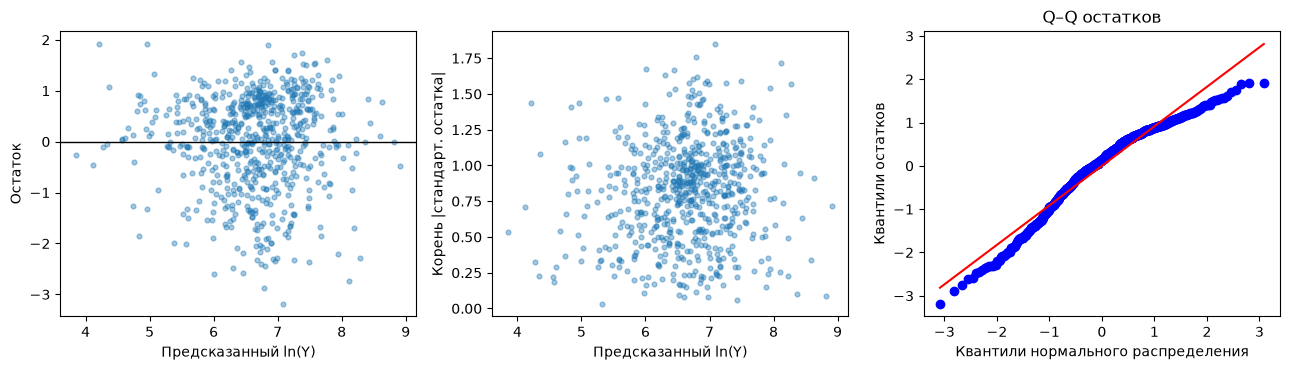

,term,min,max,full,sign_changes
0,ln_customers,0.66142,0.72185,0.68640,0
1,ln_comp_1,0.09323,0.25489,0.19483,0
2,ln_comp_2,0.15749,0.52801,0.25173,0
3,ln_comp_3,0.31651,0.57220,0.44708,0
4,ln_product_weight_g,0.23465,0.37514,0.31412,0
5,product_photos_qty,0.06448,0.14556,0.12601,0
6,product_score,-0.19210,0.12776,-0.02895,10
7,ln_volume,0.25483,0.43770,0.33534,0
8,freight_price,-0.00401,0.00708,0.00010,27


,omitted,term,coef,low,high
0,ln_volume,ln_customers,0.68736,0.55492,0.81980
1,ln_volume,ln_comp_1,0.17180,-0.12631,0.46991
2,ln_volume,ln_comp_2,0.31037,-0.25402,0.87477
3,ln_volume,ln_comp_3,0.41216,-0.02165,0.84598
4,ln_volume,ln_product_weight_g,0.39819,0.17172,0.62467
5,ln_volume,product_photos_qty,0.10029,-0.02952,0.23011
6,ln_volume,product_score,-0.00584,-0.69141,0.67972
7,ln_volume,freight_price,-0.00447,-0.02604,0.01710
8,ln_product_weight_g,ln_customers,0.68675,0.54756,0.82594
9,ln_product_weight_g,ln_comp_1,0.23111,-0.05177,0.51398


In [5]:
X = matrices['M3']
vif = pd.DataFrame({'term': FACTORS, 'vif': [variance_inflation_factor(
    X.to_numpy(), X.columns.get_loc(c)) for c in FACTORS]})
table('vif', vif)
ols, robust = fits['M3']
e = ols.resid
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].scatter(ols.fittedvalues, e, s=12, alpha=.4)
ax[0].axhline(0, color='black', lw=1)
ax[0].set(xlabel='Предсказанный ln(Y)', ylabel='Остаток')
ax[1].scatter(ols.fittedvalues, np.sqrt(abs(e / e.std())), s=12, alpha=.4)
ax[1].set(xlabel='Предсказанный ln(Y)', ylabel='Корень |стандарт. остатка|')
stats.probplot(e, dist='norm', plot=ax[2])
ax[2].set(title='Q–Q остатков', xlabel='Квантили нормального распределения',
          ylabel='Квантили остатков')
figure('diagnostics')
loo = []
for product in sorted(df.product_id.unique()):
    subset = df.loc[df.product_id != product]
    Xsub = design(subset, FACTORS, True)
    model, _ = fit_cluster(Xsub, subset)
    for term in FACTORS:
        loo.append({'removed_product': product, 'term': term,
                    'coef': model.params[term]})
loo = pd.DataFrame(loo)
loo.to_csv(ROOT / 'results' / 'leave_one_product_out.csv', index=False)
sensitivity = loo.groupby('term').coef.agg(['min','max']).reindex(FACTORS)
sensitivity['full'] = main.set_index('term').coef
sensitivity['sign_changes'] = [int((np.sign(loo.loc[loo.term == c, 'coef']) !=
    np.sign(sensitivity.loc[c, 'full'])).sum()) for c in FACTORS]
table('sensitivity', sensitivity.reset_index())
variants = []
for omit in ['ln_volume', 'ln_product_weight_g']:
    model, r = fit_cluster(design(df, [c for c in FACTORS if c != omit], True), df)
    for j, term in enumerate(model.model.exog_names):
        if term in FACTORS:
            variants.append({'omitted': omit, 'term': term,
                'coef': r.params[j], 'low': r.conf_int()[j,0], 'high': r.conf_int()[j,1]})
table('weight_volume_sensitivity', pd.DataFrame(variants))

## 5. Интерпретация
Интервалы индивидуальные (без поправки Холма). Проценты относятся к
геометрическим средним. Для рейтинга шаг 0,1 балла, для доставки — 1 единица.

,term,percent,low,high,step
38,ln_customers,6.76083,5.40389,8.13523,10%
39,ln_comp_1,1.87426,-0.89457,4.72045,10%
40,ln_comp_2,2.42826,-2.85043,7.99377,10%
41,ln_comp_3,4.35323,0.30821,8.56137,10%
42,ln_product_weight_g,3.03912,0.89603,5.22774,10%
43,product_photos_qty,13.42959,0.56333,27.94199,1
44,product_score,-0.28911,-6.22028,6.01718,0.1
45,ln_volume,3.24772,0.34808,6.23115,10%
46,freight_price,0.01047,-2.19966,2.27054,1


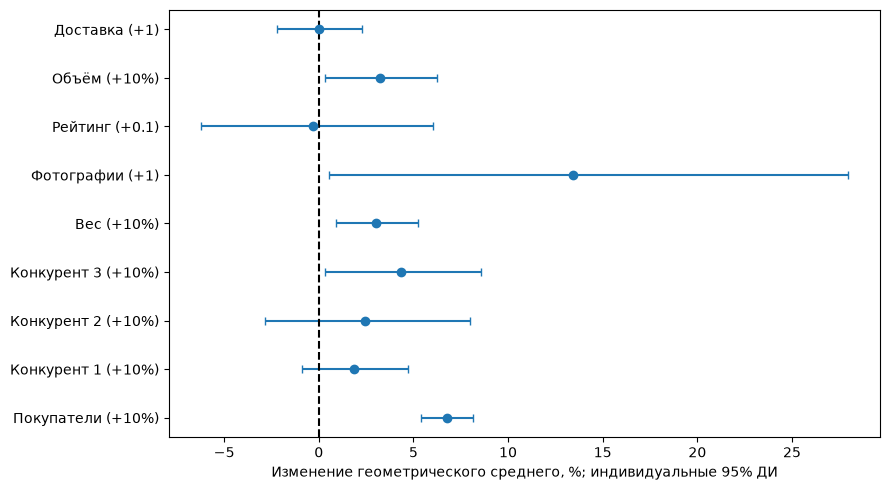

In [6]:
steps = {c: np.log(1.1) if c.startswith('ln_') else 1 for c in FACTORS}
steps['product_score'] = .1
effects = main[['term']].copy()
for source, target in [('coef','percent'), ('low','low'), ('high','high')]:
    effects[target] = [100 * np.expm1(row[source] * steps[row.term])
                       for _, row in main.iterrows()]
effects['step'] = ['10%' if c.startswith('ln_') else
                  ('0.1' if c == 'product_score' else '1') for c in FACTORS]
table('effects', effects)
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(effects.percent, range(9),
    xerr=[effects.percent-effects.low, effects.high-effects.percent], fmt='o', capsize=3)
ax.axvline(0, color='black', ls='--')
ax.set_yticks(range(9), [LABELS[c] + ' (+' + step + ')'
                         for c, step in zip(effects.term, effects.step)])
ax.set_xlabel('Изменение геометрического среднего, %; индивидуальные 95% ДИ')
figure('effects')

## 6. Проверка на исключённых товарах
Сначала GroupKFold; при отсутствии категории в обучении используем
распределение товаров внутри категорий, не обращаясь к значениям отклика.
Одинаковые разбиения для среднего, M1, M2, M3. Все метрики на лог-шкале.

,model,rmse,mae,r2,fold_rmse_sd
0,Mean,1.19948,0.98219,-0.00889,0.07731
1,M1,1.04253,0.85305,0.23786,0.07870
2,M2,1.02992,0.83346,0.25618,0.07173
3,M3,1.03252,0.83636,0.25242,0.09967


Fold allocation: category_balanced_product_folds


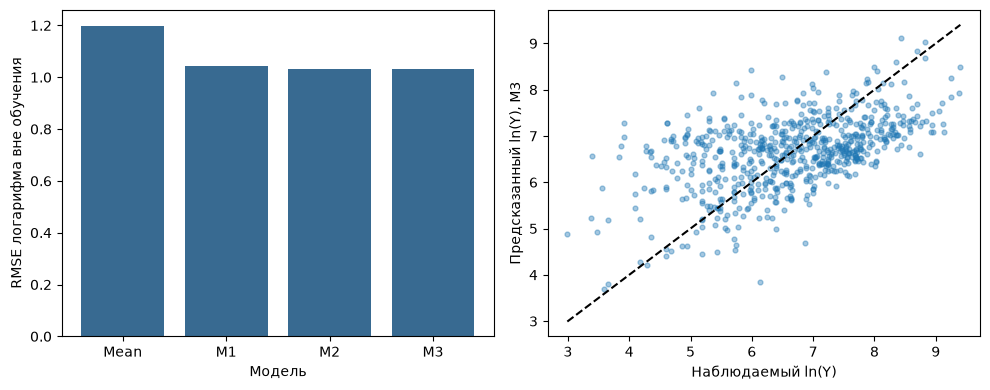

In [7]:
splits = list(GroupKFold(n_splits=5).split(df, groups=df.product_id))
def coverage_ok(splits):
    return all(set(df.iloc[tr].product_category_name) == set(categories)
               for tr, te in splits)
fold_method = 'GroupKFold'
if not coverage_ok(splits):
    fold_method = 'category_balanced_product_folds'
    products = df[['product_id', 'product_category_name']].drop_duplicates()
    rng = np.random.default_rng(SEED)
    assignment, loads = {}, np.zeros(5, dtype=int)
    for cat in sorted(categories):
        ids = products.loc[products.product_category_name == cat, 'product_id'].to_numpy()
        ids = rng.permutation(np.sort(ids))
        for start in range(0, len(ids), 5):
            order = np.argsort(loads, kind='stable')
            for product, fold in zip(ids[start:start+5], order):
                assignment[product] = int(fold)
                loads[fold] += 1
    fold_vector = df.product_id.map(assignment).to_numpy()
    splits = [(np.where(fold_vector != f)[0], np.where(fold_vector == f)[0])
              for f in range(5)]
assert coverage_ok(splits)
oof = pd.DataFrame({'product_id': df.product_id, 'observed': df.ln_total_price,
                    'fold': -1})
fold_rows = []
for fold, (tr, te) in enumerate(splits):
    train, test = df.iloc[tr], df.iloc[te]
    assert set(train.product_id).isdisjoint(set(test.product_id))
    assert len(te) > 0
    oof.loc[te, 'fold'] = fold
    preds = {'Mean': np.repeat(train.ln_total_price.mean(), len(te))}
    for name in ['M1', 'M2', 'M3']:
        factors, categorical = specs[name]
        Xtrain = design(train, factors, categorical)
        assert np.linalg.matrix_rank(Xtrain) == Xtrain.shape[1]
        fitted = sm.OLS(train.ln_total_price, Xtrain).fit()
        preds[name] = fitted.predict(design(test, factors, categorical))
    for name, pred in preds.items():
        oof.loc[te, name] = np.asarray(pred)
        fold_rows.append({'fold': fold, 'model': name, 'test_rows': len(te),
            'test_products': test.product_id.nunique(),
            'rmse': np.sqrt(mean_squared_error(test.ln_total_price, pred)),
            'mae': mean_absolute_error(test.ln_total_price, pred)})
assert (oof.fold >= 0).all() and not oof.isna().any().any()
assert oof.groupby('product_id').fold.nunique().max() == 1
oof.to_csv(ROOT / 'results' / 'oof_predictions.csv', index=False)
fold_metrics = pd.DataFrame(fold_rows)
fold_metrics.to_csv(ROOT / 'results' / 'fold_metrics.csv', index=False)
cv = pd.DataFrame([{'model': name,
    'rmse': np.sqrt(mean_squared_error(oof.observed, oof[name])),
    'mae': mean_absolute_error(oof.observed, oof[name]),
    'r2': r2_score(oof.observed, oof[name]),
    'fold_rmse_sd': fold_metrics.loc[fold_metrics.model == name, 'rmse'].std()}
    for name in ['Mean', 'M1', 'M2', 'M3']])
table('cv_metrics', cv)
print('Fold allocation:', fold_method)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(cv.model, cv.rmse, color='#386a91')
ax[0].set(ylabel='RMSE логарифма вне обучения', xlabel='Модель')
ax[1].scatter(oof.observed, oof.M3, s=12, alpha=.4)
bounds = [min(oof.observed.min(), oof.M3.min()), max(oof.observed.max(), oof.M3.max())]
ax[1].plot(bounds, bounds, 'k--')
ax[1].set(xlabel='Наблюдаемый ln(Y)', ylabel='Предсказанный ln(Y), M3')
figure('validation')

## 7. Воспроизводимость и проверки вычислений
Проверяем формулы независимо от вывода таблиц. PDF здесь не собирается.

In [8]:
r = fits['M3'][1]
np.testing.assert_allclose(r.pvalues, 2 * stats.t.sf(abs(r.tvalues), 51))
np.testing.assert_allclose(r.conf_int()[:,0], r.params-stats.t.ppf(.975,51)*r.bse)
X = matrices['M3'].to_numpy()
resid = np.asarray(fits['M3'][0].resid)
bread = np.linalg.inv(X.T @ X)
meat = np.zeros_like(bread)
for product in df.product_id.unique():
    idx = (df.product_id == product).to_numpy()
    score = X[idx].T @ resid[idx]
    meat += np.outer(score, score)
n, p = X.shape
g = df.product_id.nunique()
manual_cov = (g/(g-1))*((n-1)/(n-p))*bread @ meat @ bread
np.testing.assert_allclose(manual_cov, r.cov_params(), rtol=1e-6, atol=1e-8)
manual_beta = np.linalg.lstsq(X, df.ln_total_price, rcond=None)[0]
np.testing.assert_allclose(manual_beta, r.params, rtol=1e-8, atol=1e-8)
manifest = {'checks': checks, 'seed': SEED, 'fold_method': fold_method,
    'time_sensitivity': {'reference_month': str(month_labels.min()),
                         'month_indicators': month_indicators.shape[1]},
    'sha256': hashlib.sha256((ROOT/'retail_price.csv').read_bytes()).hexdigest(),
    'versions': {p: importlib.metadata.version(p) for p in
                 ['numpy','pandas','scipy','statsmodels','scikit-learn']},
    'validated': ['OLS coefficients', 'cluster CR1 covariance', 't p-values',
                  'confidence intervals', 'group separation', 'category coverage',
                  'full rank training matrices', 'complete OOF predictions']}
(ROOT/'results'/'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2))
print('Completed:', json.dumps(manifest, ensure_ascii=False, indent=2))

Completed: {
  "checks": {
    "rows": 676,
    "products": 52,
    "categories": 9,
    "months": 20,
    "missing": 0,
    "duplicates": 0,
    "duplicate_product_month": 0,
    "nonpositive_log_values": 0,
    "negative_freight": 0,
    "zero_freight": 1,
    "calendar_mismatch": 0,
    "identity_within_0_3_percent": 643,
    "identity_max_gap": 0.03058306418099551,
    "category_month_customer_max_unique": 1,
    "start": "2017-01-01",
    "end": "2018-08-01",
    "base_category": "garden_tools"
  },
  "seed": 20261030,
  "fold_method": "category_balanced_product_folds",
  "time_sensitivity": {
    "reference_month": "2017-01",
    "month_indicators": 19
  },
  "sha256": "a1cd6562c1d65db5abecf57fa7084f8fee8ea13e88df64dd56bcf0de75b09461",
  "versions": {
    "numpy": "2.5.4",
    "pandas": "3.0.6",
    "scipy": "1.18.1",
    "statsmodels": "0.15.0",
    "scikit-learn": "1.9.1"
  },
  "validated": [
    "OLS coefficients",
    "cluster CR1 covariance",
    "t p-values",
    "confiden